# LAB | Intro to Machine Learning

**Load the data**

In this challenge, we will be working with Spaceship Titanic data. The data can be found here:

https://raw.githubusercontent.com/data-bootcamp-v4/data/main/spaceship_titanic.csv

Metadata

https://github.com/data-bootcamp-v4/data/blob/main/spaceship_titanic.md

In [15]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

In [3]:
spaceship = pd.read_csv("https://raw.githubusercontent.com/data-bootcamp-v4/data/main/spaceship_titanic.csv")
spaceship.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


**Check the shape of your data**

In [4]:
#your code here
spaceship.shape

(8693, 14)

**Check for data types**

In [5]:
#your code here
spaceship.dtypes

PassengerId      object
HomePlanet       object
CryoSleep        object
Cabin            object
Destination      object
Age             float64
VIP              object
RoomService     float64
FoodCourt       float64
ShoppingMall    float64
Spa             float64
VRDeck          float64
Name             object
Transported        bool
dtype: object

**Check for missing values**

In [6]:
#your code here
spaceship_missing = spaceship[spaceship.isna().any(axis=1)]
spaceship_missing

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
7,0006_02,Earth,True,G/0/S,TRAPPIST-1e,28.0,False,0.0,0.0,0.0,0.0,NaN,Candra Jacostaffey,True
10,0008_02,Europa,True,B/1/P,TRAPPIST-1e,34.0,False,0.0,0.0,NaN,0.0,0.0,Altardr Flatic,True
15,0012_01,Earth,False,NaN,TRAPPIST-1e,31.0,False,32.0,0.0,876.0,0.0,0.0,Justie Pooles,False
16,0014_01,Mars,False,F/3/P,55 Cancri e,27.0,False,1286.0,122.0,NaN,0.0,0.0,Flats Eccle,False
23,0020_03,Earth,True,E/0/S,55 Cancri e,29.0,False,0.0,0.0,NaN,0.0,0.0,Mollen Mcfaddennon,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8667,9250_01,Europa,False,E/597/P,TRAPPIST-1e,29.0,False,0.0,2972.0,NaN,28.0,188.0,Chain Reedectied,True
8674,9257_01,NaN,False,F/1892/P,TRAPPIST-1e,13.0,False,39.0,0.0,1085.0,24.0,0.0,Ties Apple,False
8675,9259_01,Earth,NaN,F/1893/P,TRAPPIST-1e,44.0,False,1030.0,1015.0,0.0,11.0,NaN,Annah Gilleyons,True
8684,9274_01,NaN,True,G/1508/P,TRAPPIST-1e,23.0,False,0.0,0.0,0.0,0.0,0.0,Chelsa Bullisey,True


In [18]:
spaceship.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


There are multiple strategies to handle missing data

- Removing all rows or all columns containing missing data.
- Filling all missing values with a value (mean in continouos or mode in categorical for example).
- Filling all missing values with an algorithm.

For this exercise, because we have such low amount of null values, we will drop rows containing any missing value. 

In [7]:
#Drop NA values from dataframe
spaceship = spaceship.dropna()

**KNN**

K Nearest Neighbors is a distance based algorithm, and requeries all **input data to be numerical.**

Let's only select numerical columns as our features.

In [8]:
#your code here
spaceship_num = spaceship[["Age", "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]]

And also lets define our target.

In [9]:
#your code here
X_spaceship = spaceship_num
y_spaceship = spaceship["Transported"]

**Train Test Split**

Now that we have split the data into **features** and **target** variables and imported the **train_test_split** function, split X and y into X_train, X_test, y_train, and y_test. 80% of the data should be in the training set and 20% in the test set.

In [10]:
#your code here
X_train_spaceship, X_test_spaceship, y_train_spaceship, y_test_spaceship = train_test_split(
    X_spaceship,
    y_spaceship,
    test_size=0.20,
    random_state=0,
    stratify=y_spaceship,
)

print("Training observations:", len(X_train_spaceship))
print("Test observations:", len(X_test_spaceship))
print("Training features:", list(X_train_spaceship.columns))

Training observations: 5284
Test observations: 1322
Training features: ['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']


**Model Selection**

In this exercise we will be using **KNN** as our predictive model.

You need to choose between **Classificator** or **Regressor**. Take into consideration target variable to decide.

Initialize a KNN instance without setting any hyperparameter.

In [11]:
#your code here
knn_classifier = KNeighborsClassifier()

Fit the model to your data.

In [12]:
#Use knn_classifier to train the KNN model and generate predictions with KNN model using test data
knn_classifier.fit(X_train_spaceship, y_train_spaceship)
y_pred_test_knn = knn_classifier.predict(X_test_spaceship)

Evaluate your model.

,actual_transport_status,predicted_transport_status
2236,Stayed,Stayed
2523,Transported,Transported
2204,Transported,Transported
8069,Stayed,Stayed
404,Stayed,Stayed
7335,Stayed,Stayed
1941,Stayed,Stayed
8259,Transported,Stayed
5737,Stayed,Transported
1068,Stayed,Transported


,Training,Test
Accuracy,0.799,0.781
Precision (macro),0.788,0.770
Recall (macro),0.821,0.806


Per-class classification report (test set):
              precision    recall  f1-score   support

      Stayed       0.79      0.76      0.77       656
 Transported       0.77      0.81      0.79       666

    accuracy                           0.78      1322
   macro avg       0.78      0.78      0.78      1322
weighted avg       0.78      0.78      0.78      1322



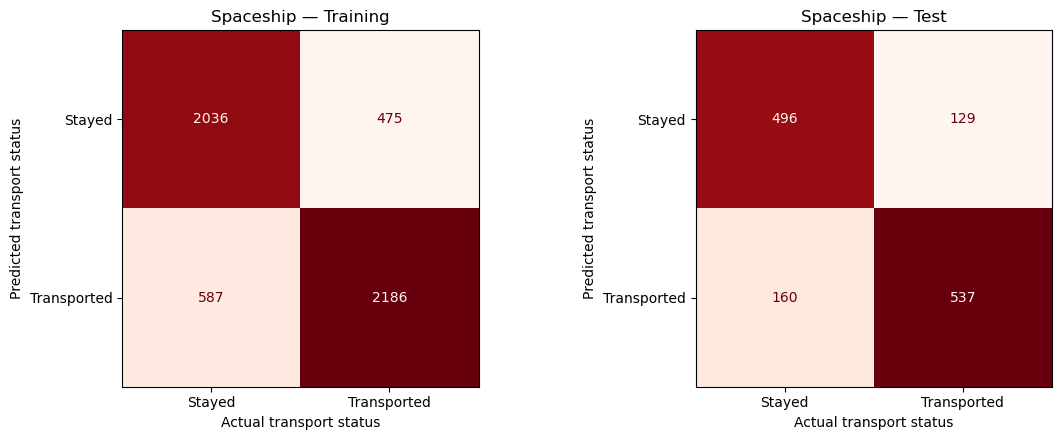

In [17]:
#Compare actual transport status data vs KNN model predictions from same x-value test data
comparison_spaceship = pd.DataFrame({
    "actual_transport_status": y_test_spaceship.map({False: "Stayed", True: "Transported"}),
    "predicted_transport_status": pd.Series(y_pred_test_knn, index=y_test_spaceship.index).map({False: "Stayed", True: "Transported"})
    ,
})
display(comparison_spaceship.head(10))

#Generate predictions from KNN model with training data
y_pred_train_knn = knn_classifier.predict(X_train_spaceship)

# Determine the accuracy, precision, and recall of the KNN model with both training and test data
classification_metrics = pd.DataFrame({
    "Training": {
        "Accuracy": accuracy_score(y_train_spaceship, y_pred_train_knn),
        "Precision (macro)": precision_score(y_train_spaceship, y_pred_train_knn, pos_label=1),
        "Recall (macro)": recall_score(y_train_spaceship, y_pred_train_knn, pos_label=1),
    },
    "Test": {
        "Accuracy": accuracy_score(y_test_spaceship, y_pred_test_knn),
        "Precision (macro)": precision_score(y_test_spaceship, y_pred_test_knn, pos_label=1),
        "Recall (macro)": recall_score(y_test_spaceship, y_pred_test_knn, pos_label=1),
    },
})

display(classification_metrics.round(3))

# Determine the same per classification
print("Per-class classification report (test set):")
print(classification_report(
    y_test_spaceship,
    y_pred_test_knn,
    target_names=["Stayed", "Transported"],
    zero_division=0,
))

# Compute confusion matrices for both datasets; we will display them together
# in the overfitting/underfitting section below.
cm_train_spaceship = confusion_matrix(y_train_spaceship, y_pred_train_knn)
cm_test_spaceship = confusion_matrix(y_test_spaceship, y_pred_test_knn)

#Plot the confusion matrices: test vs train
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, cm, split_name in zip(
    axes,
    [cm_train_spaceship, cm_test_spaceship],
    ["Training", "Test"],
):
    # Transpose: predicted classes on rows, actual classes on columns.
    ConfusionMatrixDisplay(
        confusion_matrix=cm.T,
        display_labels=["Stayed", "Transported"],
    ).plot(ax=ax, cmap="Reds", values_format="d", colorbar=False)
    ax.set_xlabel("Actual transport status")
    ax.set_ylabel("Predicted transport status")
    ax.set_title(f"Spaceship — {split_name}")

plt.tight_layout()
plt.show()

**Congratulations, you have just developed your first Machine Learning model!**